In [2]:
from cellpose import models, io
dir(models)

['CellposeModel',
 'MODEL_DIR',
 'MODEL_LIST_PATH',
 'MODEL_NAMES',
 'Path',
 'Transformer',
 '_CPSAM_MODEL_URL',
 '_MODEL_DIR_DEFAULT',
 '_MODEL_DIR_ENV',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 'assign_device',
 'cache_CPSAM_model_path',
 'cv2',
 'dynamics',
 'gaussian_filter',
 'gc',
 'get_user_models',
 'logging',
 'model_path',
 'models_logger',
 'normalize_default',
 'np',
 'os',
 'plot',
 'run_3D',
 'run_net',
 'time',
 'torch',
 'trange',
 'transforms',
 'utils']

In [1]:
from cellpose import models, io
import tifffile
import pickle
# Extract polygons (like polys_FullSection.pckl)
import numpy as np
from skimage.measure import find_contours

# Load image
img = tifffile.imread("../data/CRC_P1/image.tif")

# Load model (cyto = cell; nuclei = nuclear)
model = models.CellposeModel(model_type='cyto', gpu=True)   # or 'nuclei'

# Run segmentation
masks, flows, styles = model.eval(img, diameter=None, channels=[0,0])

# Save label image (like labels_FullSection.pckl)
with open("labels_FullSection.pckl", "wb") as f:
    pickle.dump(masks, f)

polys = {"coord": []}

for label_id in np.unique(masks):
    if label_id == 0:
        continue  # background

    mask = masks == label_id
    contours = find_contours(mask, 0.5)

    if contours:
        contour = max(contours, key=lambda x: x.shape[0])
        y_coords, x_coords = contour[:, 0], contour[:, 1]
        polys["coord"].append([y_coords, x_coords])

with open("polys_FullSection.pckl", "wb") as f:
    pickle.dump(polys, f)




Welcome to CellposeSAM, cellpose v
cellpose version: 	4.0.4 
platform:       	linux 
python version: 	3.11.9 
torch version:  	2.7.1+cu126! The neural network component of
CPSAM is much larger than in previous versions and CPU excution is slow. 
We encourage users to use GPU/MPS if available. 




model_type argument is not used in v4.0.1+. Ignoring this argument...
channels deprecated in v4.0.1+. If data contain more than 3 channels, only the first 3 channels will be used


In [2]:
import pickle
import pandas as pd
import numpy as np

# Load cell polygons
with open("output/CRC_P1/polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)

# Load patch metadata CSV
patch_df = pd.read_csv("../uni/notebooks/WSI_patch_metadata.csv")

PATCH_SIZE = 224

# Check for required columns
required_cols = {'Patch_ID', 'X', 'Y'}
#assert required_cols.issubset(patch_df.columns), f"CSV must contain columns: {required_cols}"

# Convert patch positions to bounding boxes
patch_boxes = []
for _, row in patch_df.iterrows():
    patch_id = row['Patch_ID']
    x0, y0 = row['X'], row['Y']
    x1, y1 = x0 + PATCH_SIZE, y0 + PATCH_SIZE
    patch_boxes.append((patch_id, x0, y0, x1, y1))

# Associate each cell with a patch
cell_to_patch = []
unassigned_count = 0

for cell_idx, (y_coords, x_coords) in enumerate(polys["coord"]):
    coords = np.stack([x_coords, y_coords], axis=1)  # shape: (N, 2)

    if coords.size == 0:
        continue

    max_overlap = 0
    best_patch = None

    for patch_id, x0, y0, x1, y1 in patch_boxes:
        # Check which points fall inside the patch
        inside = (
            (coords[:, 0] >= x0) & (coords[:, 0] < x1) &
            (coords[:, 1] >= y0) & (coords[:, 1] < y1)
        )
        overlap = np.sum(inside)

        if overlap > max_overlap:
            max_overlap = overlap
            best_patch = patch_id

    total_points = coords.shape[0]
    overlap_pct = (max_overlap / total_points) if total_points > 0 else 0

    if best_patch is not None and max_overlap > 0:
        cell_to_patch.append({
            "cell_id": cell_idx,
            "patch_id": best_patch,
            "overlap_percent": overlap_pct
        })
    else:
        unassigned_count += 1


# Save as pickle
with open("cell_to_patch_mapping.pckl", "wb") as f:
    pickle.dump(cell_to_patch, f)

# Save as CSV
pd.DataFrame(cell_to_patch).to_csv("output/CRC_P1/cell_to_patch_mapping.csv", index=False)

# Report
print(f"Number of cells not assigned to any patch: {unassigned_count}")


Number of cells not assigned to any patch: 0


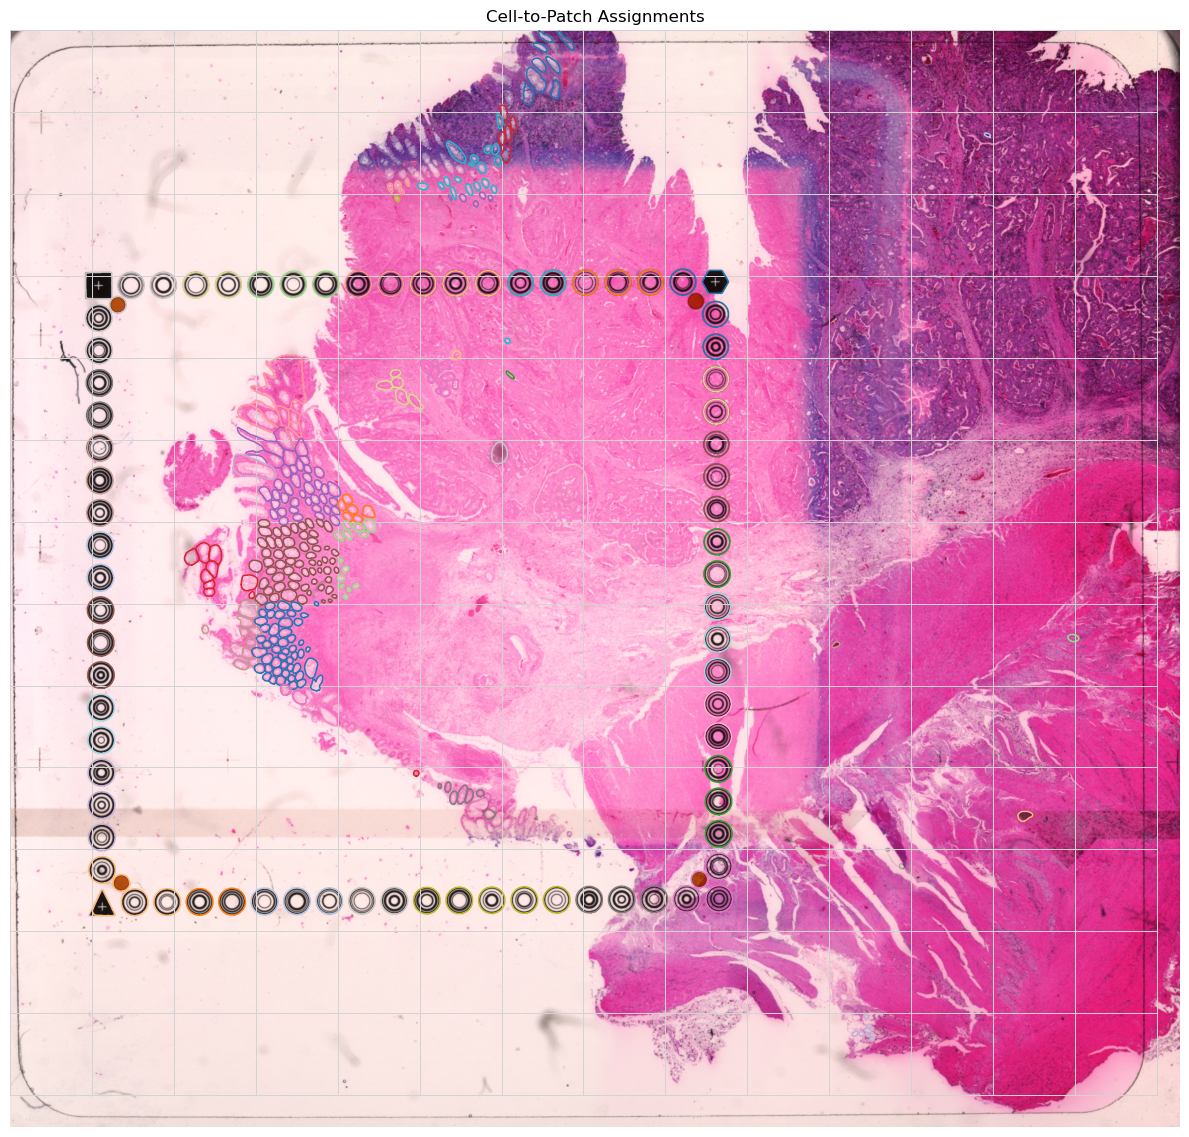

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

# Optional: Load the image if you want to display it under the polygons
from tifffile import imread
img = imread("../data/CRC_P1/image.tif")

# Convert patch list to dict for easy color lookup
patch_ids = list(set([d["patch_id"] for d in cell_to_patch]))
patch_to_color = {pid: plt.cm.tab20(i % 20) for i, pid in enumerate(patch_ids)}

# Create a figure
fig, ax = plt.subplots(figsize=(12, 12))

# Optional: Show background image
ax.imshow(img, cmap='gray')

# Draw patch boundaries (optional)
for patch_id, x0, y0, x1, y1 in patch_boxes:
    rect = patches.Rectangle((x0, y0), PATCH_SIZE, PATCH_SIZE, linewidth=0.5,
                             edgecolor='lightgray', facecolor='none')
    ax.add_patch(rect)

# Draw cells
for cell in cell_to_patch:
    cell_id = cell["cell_id"]
    patch_id = cell["patch_id"]
    color = patch_to_color[patch_id]

    y_coords, x_coords = polys["coord"][cell_id]
    ax.plot(x_coords, y_coords, color=color, linewidth=1)

# Formatting
ax.set_title("Cell-to-Patch Assignments")
ax.set_aspect('equal')
plt.axis('off')
plt.tight_layout()
plt.show()
